# Toy-track obstacle detector — training notebook (Prototype / MVP car)

Detects the obstacles of **our own track** in the ESP32-CAM image, so the toy car (Prototype mode of the dashboard) reacts to them.

| Class | Object |
|---|---|
| `column` | striped taped column with a black top |
| `box` | cream "Mutesa" box (red logo on one face) |

### Data — our own video
* **249 frames** filmed at car height while following the black tape (`datasets/toy/raw/frames`).
* **Automatic labels with SAM 2** (`toy_autolabel.py`): one click on each obstacle in a reference frame, SAM 2 follows it through the video and gives its exact outline → 141 boxes, every one checked visually. Frames without an obstacle are kept as *empty track* examples.
* **Split in time blocks** (`toy_dataset.py`): the video is one continuous drive, neighbouring frames are almost identical, so whole blocks go to validation / test, with gaps — no near-duplicate frame is shared between splits.
* **The ESP32-CAM streams 320 × 240 (4:3)** while the video is 832 × 464 (16:9, phone): the model is trained at **320 px**, and training images are turned into **ESP32-CAM-style frames** (random 4:3 crop → 320 × 240, boxes adjusted, softer image, colour cast, noise, strong JPEG).
* **Copy-paste** (training only): obstacles cut out with their SAM outline and pasted on empty-track frames at new places and distances.
* **Two test sets**: the real test frames, and the same frames converted to 320 × 240 ESP32-CAM style (`test_esp32`).

### ▶ How to run it
Same Docker kernel as the other notebook: `docker compose --profile train up -d trainer`, then *Select Kernel → Existing Jupyter Server* → `http://localhost:8888/?token=smartcar` → **Run All**. About **15–20 min** on the GTX 1650 Ti (320 px images train fast).

⚠️ The test set is small (26 frames from the same drive): numbers are a first indication. For a solid result, film a **second drive** (other obstacle positions / light) and use it as the test set.

In [1]:
# Parameters
MODEL = "yolo26n.pt"      # nano: analyses the ESP32-CAM stream live on the laptop CPU in a few ms
EPOCHS = 80
IMGSZ = 320               # = the ESP32-CAM resolution (320 x 240): train at the size the model will see
BATCH = 16
PATIENCE = 30
SYNTH_IMAGES = 400        # copy-paste training images
DEGRADE_P = 0.6           # share of training images turned into 320 x 240 ESP32-CAM-style frames
SEED = 0
RELABEL = False           # True = run SAM 2 auto-labelling again (after changing toy_autolabel.py)

In [2]:
# Check that this notebook runs on the Docker kernel
from pathlib import Path
if not Path("/workspace/training").exists():
    raise SystemExit("Wrong kernel: Select Kernel -> Existing Jupyter Server -> http://localhost:8888/?token=smartcar")
print("OK — running on the Docker trainer kernel")

OK — running on the Docker trainer kernel


In [3]:
import json, shutil, sys, time
from datetime import date

import cv2
import matplotlib.pyplot as plt
import torch
import ultralytics
from IPython.display import Image, display
from ultralytics import YOLO

sys.path.insert(0, "/workspace/training")
import importlib
import toy_autolabel, toy_dataset as td
td, toy_autolabel = importlib.reload(td), importlib.reload(toy_autolabel)   # always use the latest version on disk

DS = Path("/datasets/toy_obstacles")         # prepared dataset (Docker volume)
RUNS = Path("/workspace/training/runs")
MODELS = Path("/workspace/models")
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print(f"ultralytics {ultralytics.__version__} · GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}")

def show(img, title="", w=16):
    plt.figure(figsize=(w, w * img.shape[0] / img.shape[1])); plt.imshow(img[..., ::-1]); plt.axis("off"); plt.title(title); plt.show()

ultralytics 8.4.184 · GPU: NVIDIA GeForce GTX 1650 Ti


## 1 · Labels (SAM 2 video tracking)

248 labelled frames · 141 with an obstacle · 107 empty track
auto_1_column_001-042.jpg


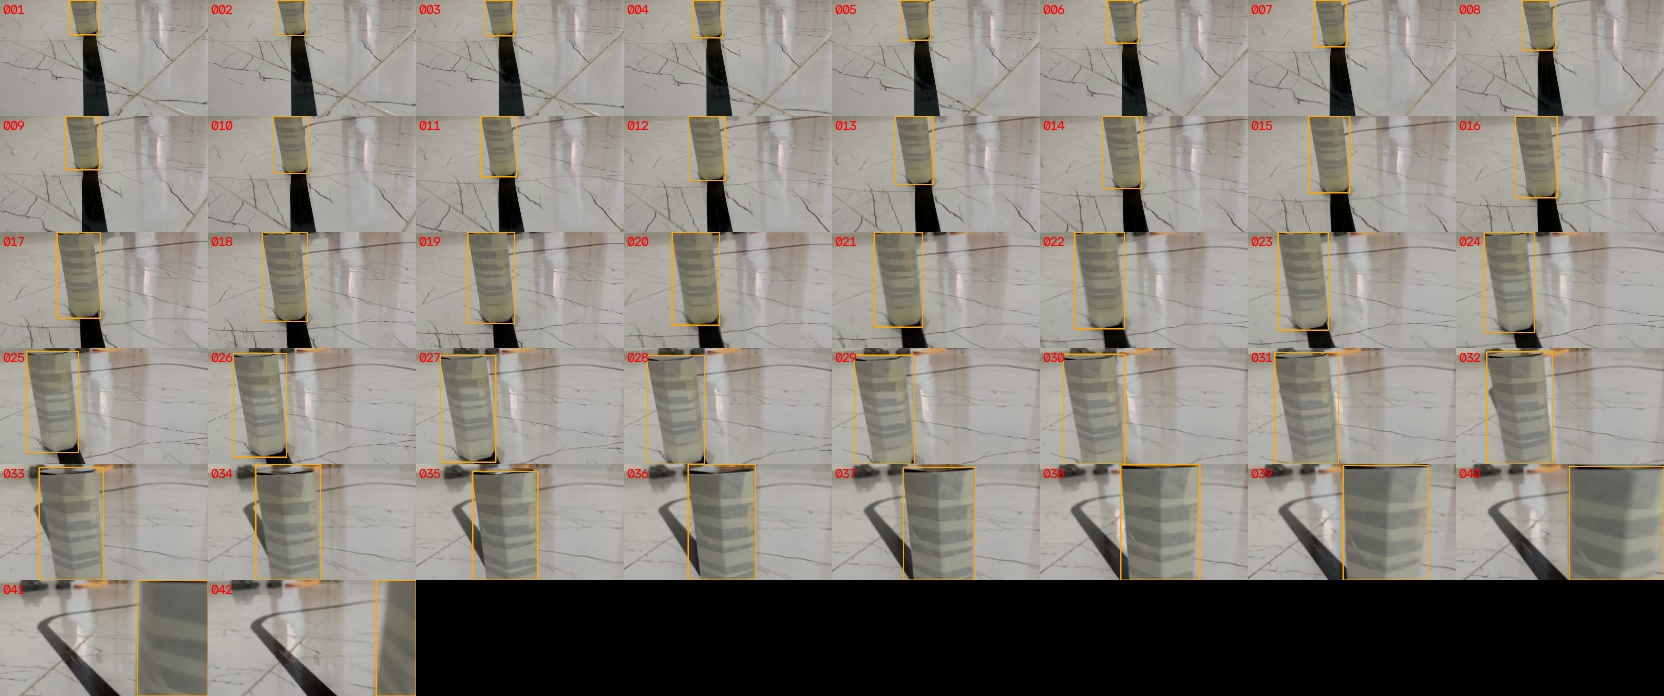

auto_2_box_087-157.jpg


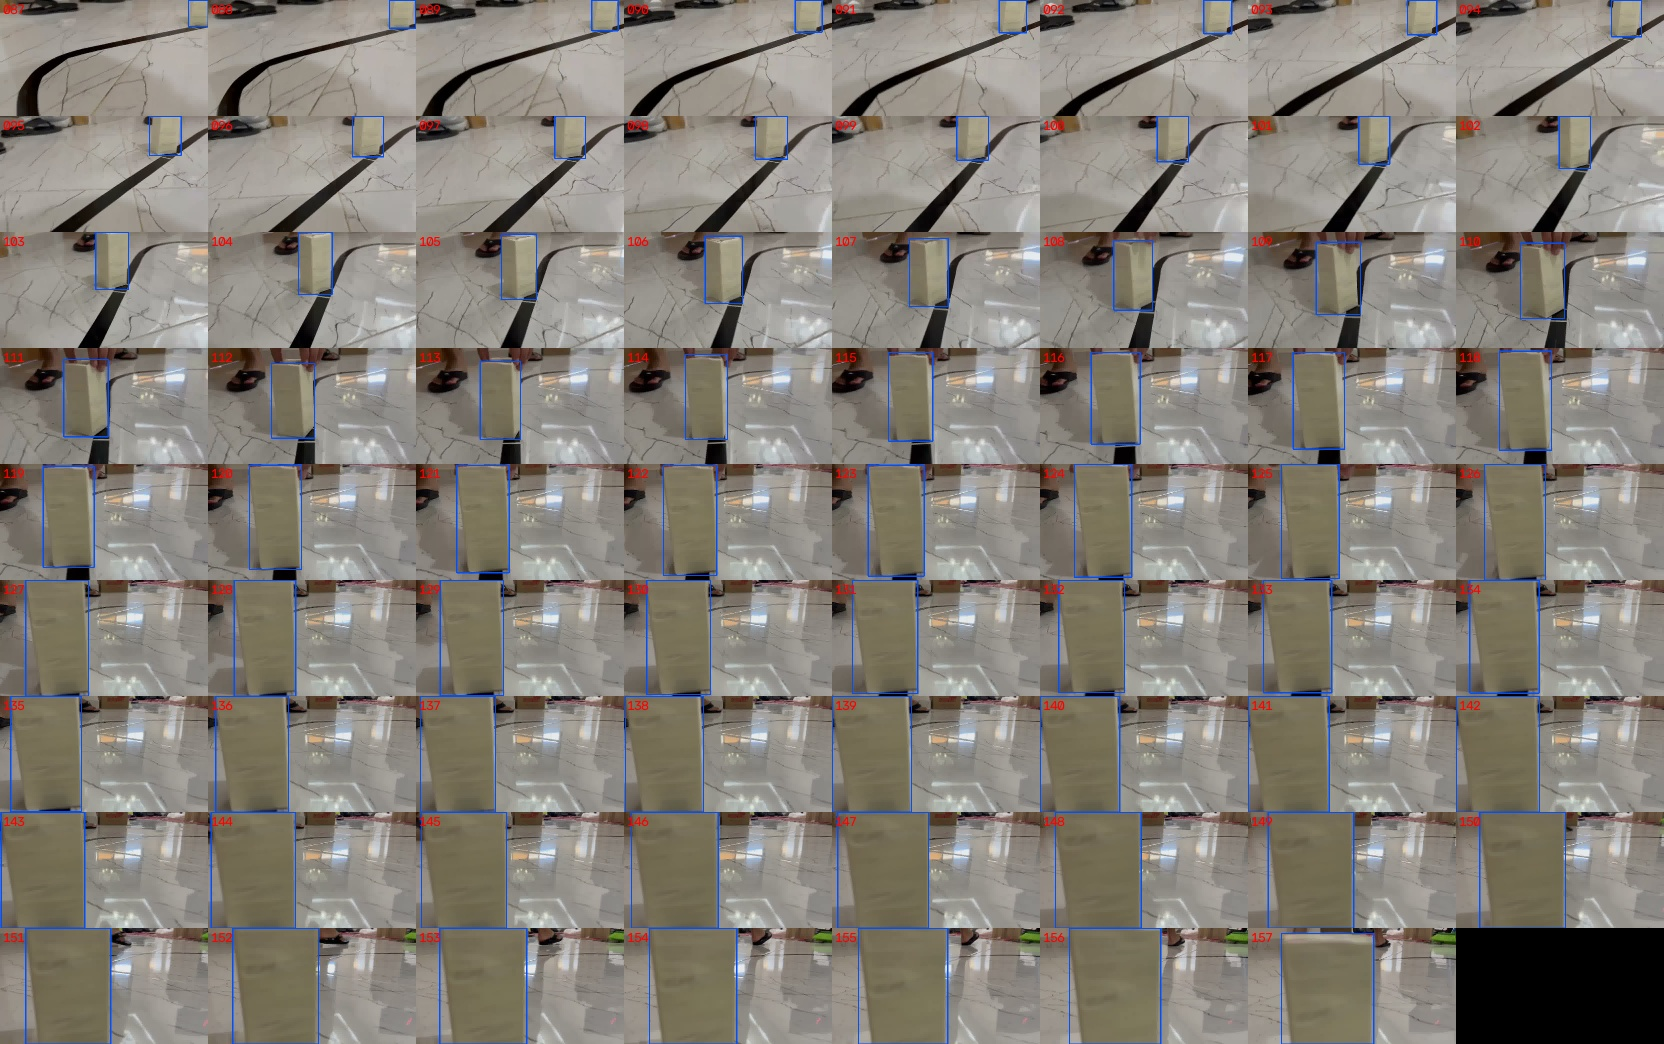

auto_3_box_158-170.jpg


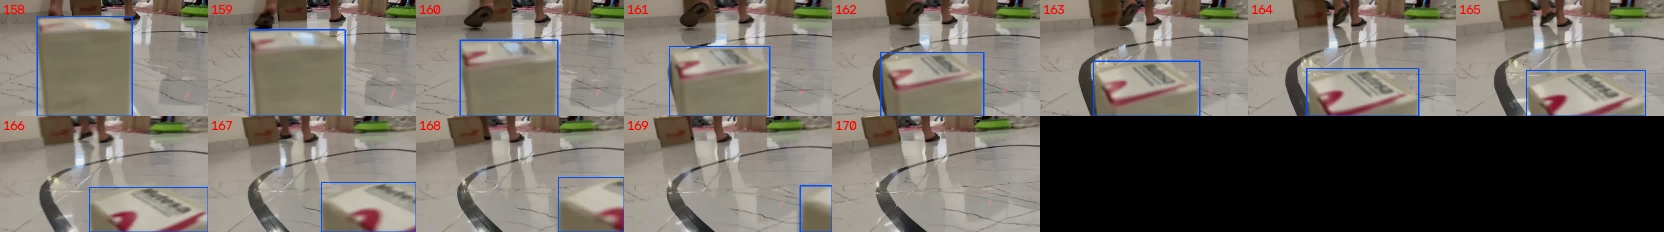

auto_4_column_223-238.jpg


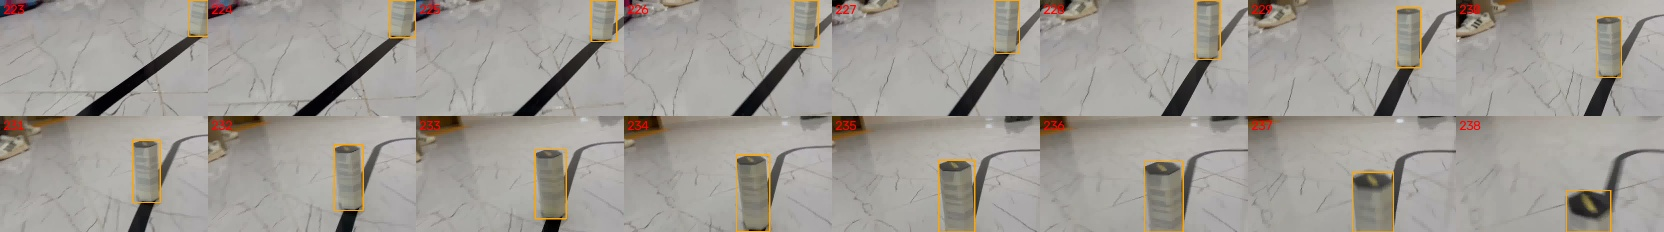

In [4]:
if RELABEL or not any(td.LABELS.glob("*.txt")):
    toy_autolabel.main()
labels = list(td.LABELS.glob("*.txt"))
with_box = sum(1 for f in labels if f.read_text().strip())
print(f"{len(labels)} labelled frames · {with_box} with an obstacle · {len(labels) - with_box} empty track")
for f in sorted((td.ROOT / "raw" / "review").glob("auto_*.jpg")):
    print(f.name); display(Image(filename=str(f), width=1100))

## 2 · Dataset: time-block split, ESP32-CAM look, copy-paste

clean obstacle cut-outs used for copy-paste: 8
train: {'real': 169, 'obstacles': 98, 'empty': 71, 'esp32_look': 96, 'pasted': 400}
  val: {'real': 26, 'obstacles': 15, 'empty': 11, 'esp32_look': 0, 'pasted': 0}
 test: {'real': 26, 'obstacles': 15, 'empty': 11, 'esp32_look': 0, 'pasted': 0}
test_esp32: {'real': 26, 'obstacles': 15, 'empty': 11, 'esp32_look': 0, 'pasted': 0}


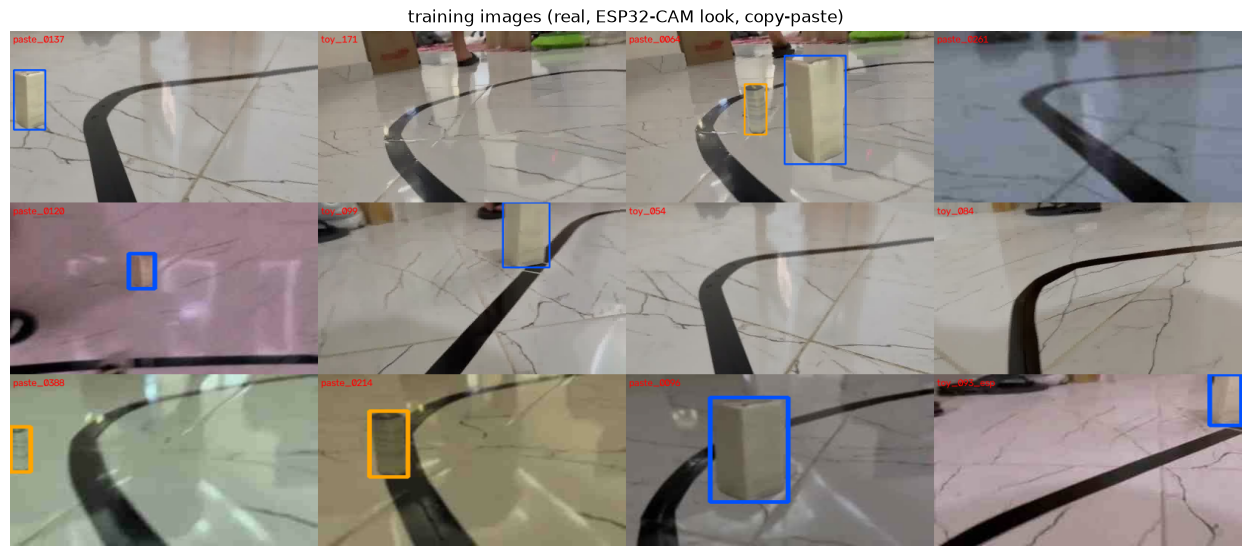

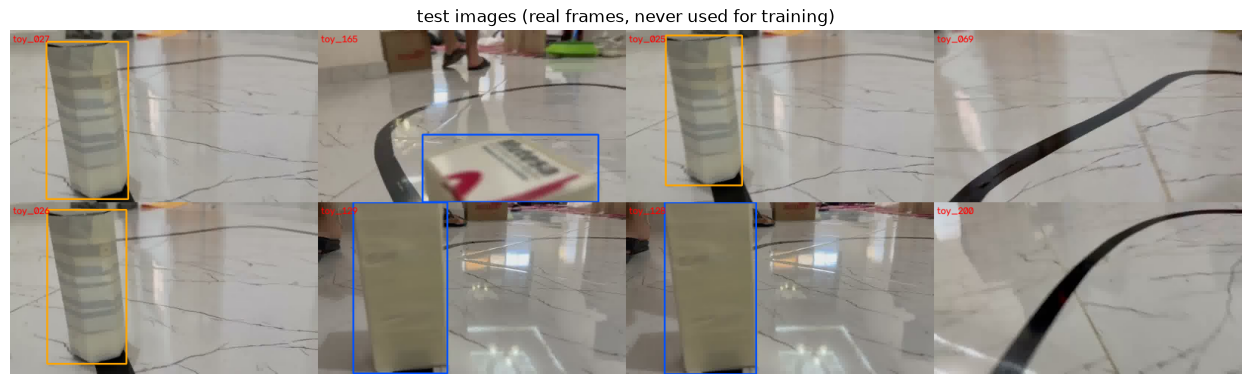

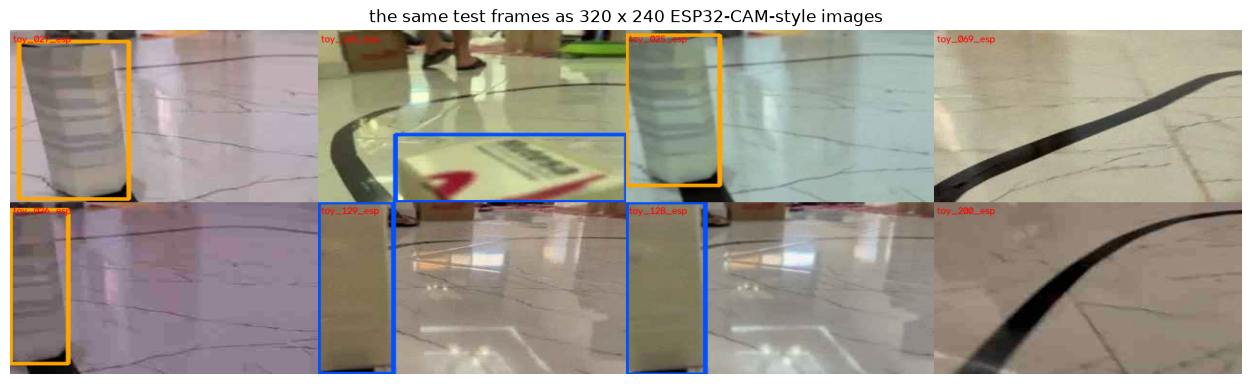

In [5]:
counts, n_pieces = td.build(DS, degrade_p=DEGRADE_P, synth_n=SYNTH_IMAGES, seed=SEED)
print(f"clean obstacle cut-outs used for copy-paste: {n_pieces}")
for split, c in counts.items():
    print(f"{split:>5}: {c}")
show(td.preview(DS, "train", n=12), "training images (real, ESP32-CAM look, copy-paste)")
show(td.preview(DS, "test", n=8), "test images (real frames, never used for training)")
show(td.preview(DS, "test_esp32", n=8), "the same test frames as 320 x 240 ESP32-CAM-style images")

## 3 · Train on the GPU

Ultralytics 8.4.184 🚀 Python-3.12.3 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 4096MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/datasets/toy_obstacles/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=toy_obstacles, nbs=64, nms=None, opset=No

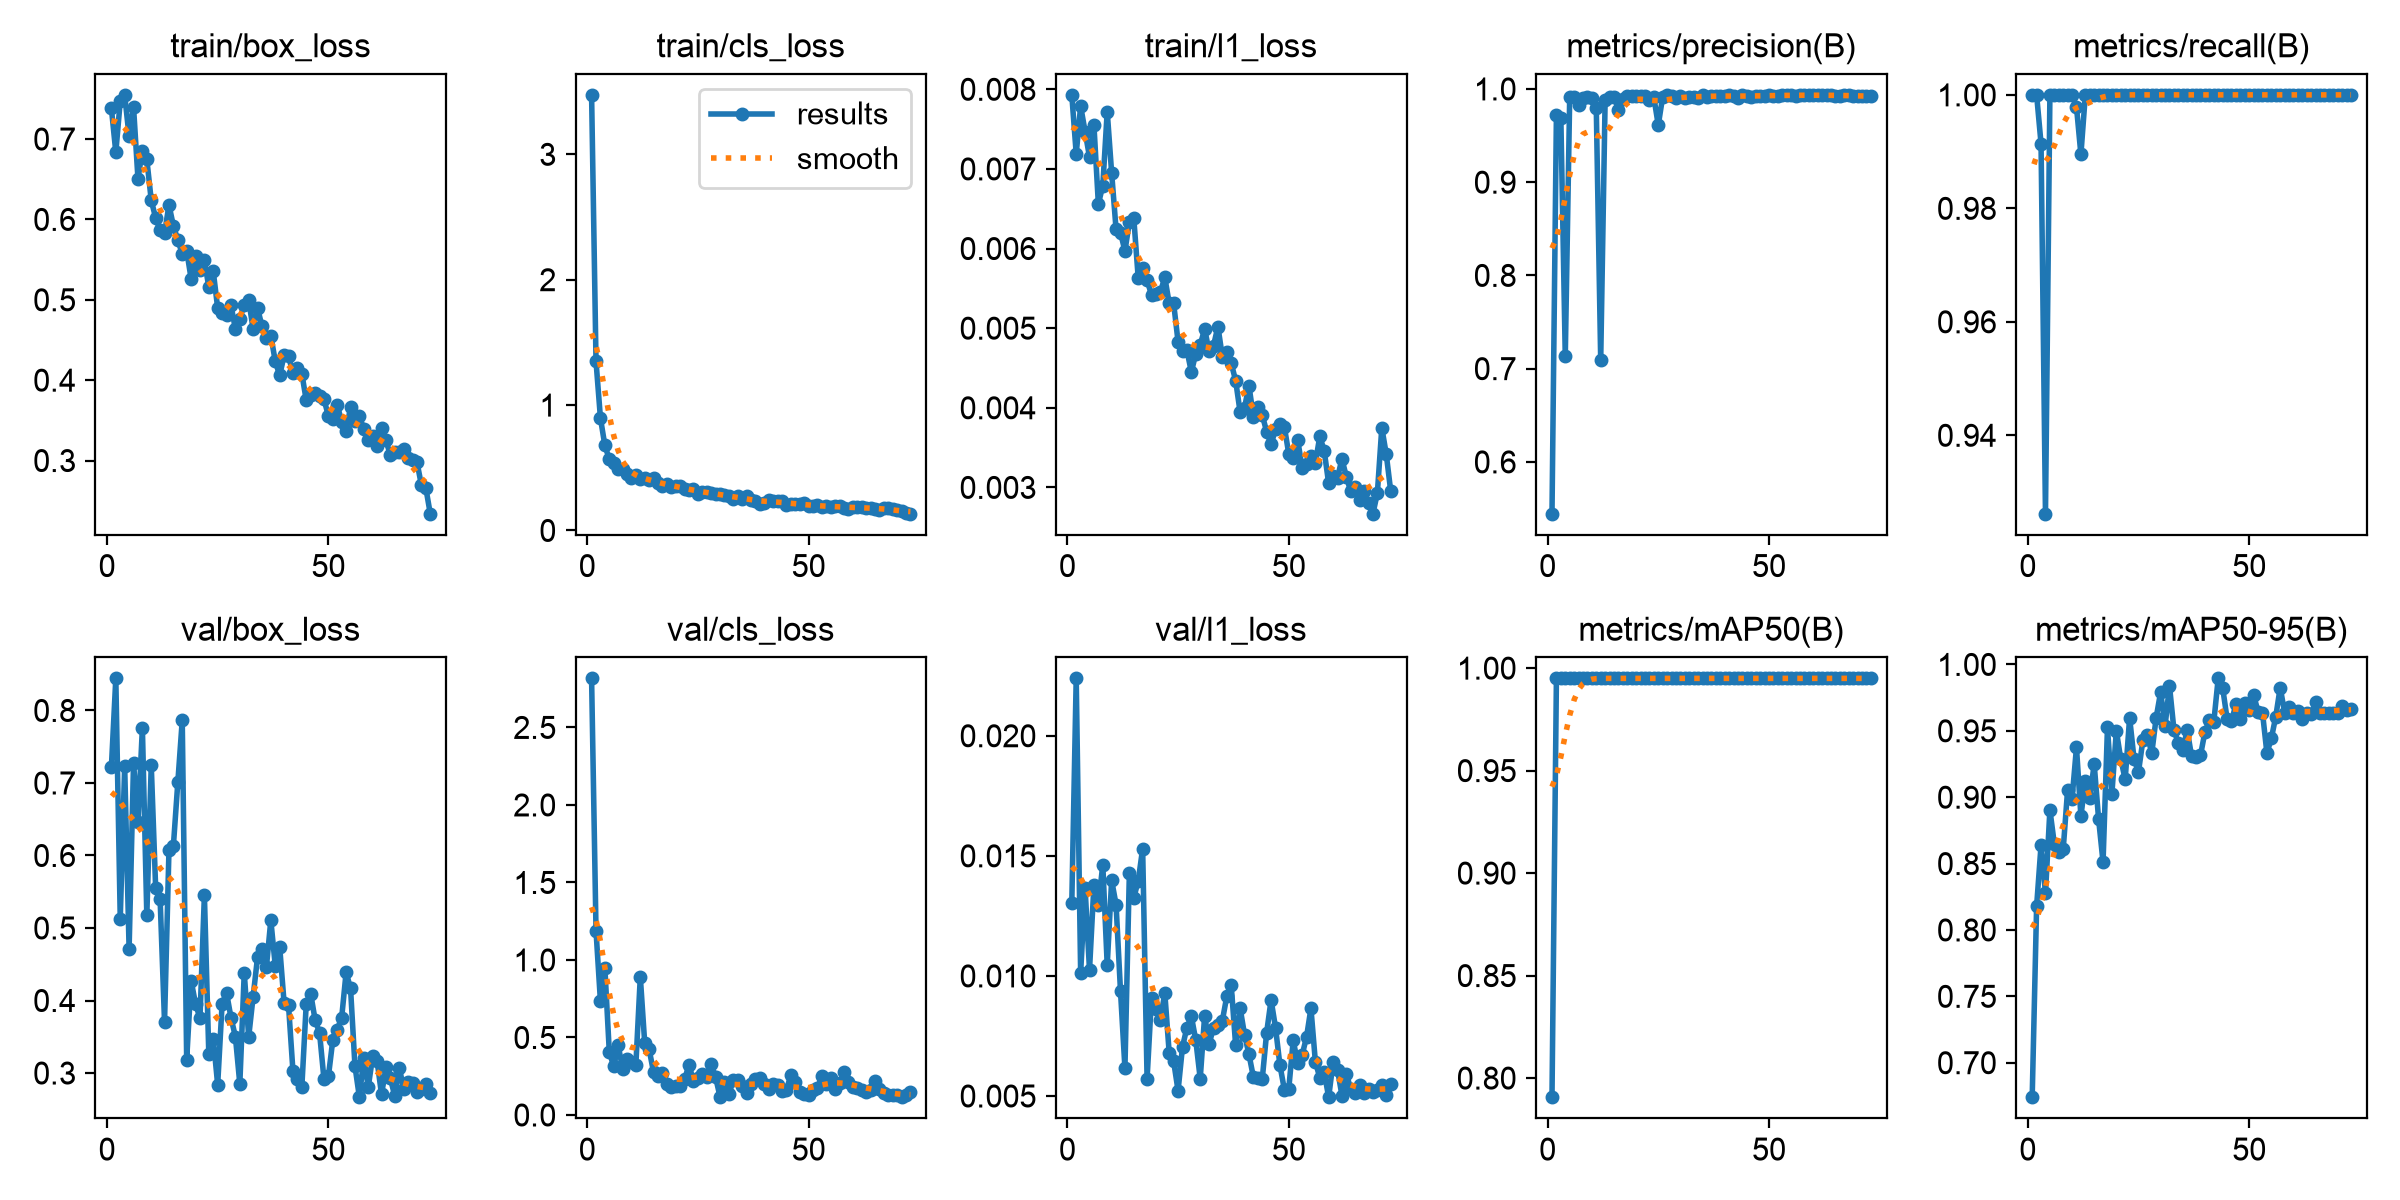

In [6]:
model = YOLO(MODEL)
t0 = time.time()
model.train(data=str(DS / "data.yaml"), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, device=DEVICE, patience=PATIENCE,
            seed=SEED, cos_lr=True, close_mosaic=10, plots=True, project=str(RUNS), name="toy_obstacles", exist_ok=True)
TRAIN_MINUTES = (time.time() - t0) / 60
BEST = RUNS / "toy_obstacles" / "weights" / "best.pt"
print(f"training took {TRAIN_MINUTES:.0f} min · {model.trainer.epoch + 1} epochs")
display(Image(filename=str(RUNS / "toy_obstacles" / "results.png"), width=1000))

## 4 · Evaluate on the held-out test frames (real, and as 320 × 240 ESP32-CAM frames)

Ultralytics 8.4.184 🚀 Python-3.12.3 torch-2.14.1+cu132 CUDA:0 (NVIDIA GeForce GTX 1650 Ti, 4096MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 6.5±4.3 MB/s, size: 18.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /datasets/toy_obstacles/labels/test... 26 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 26/26 314.7it/s 0.1s
val: New cache created: /datasets/toy_obstacles/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.3it/s 1.6s3.6s
                   all         26         15      0.989          1      0.995      0.976
                column          6          6      0.982          1      0.995      0.979
                   box          9          9      0.996          1      0.995   

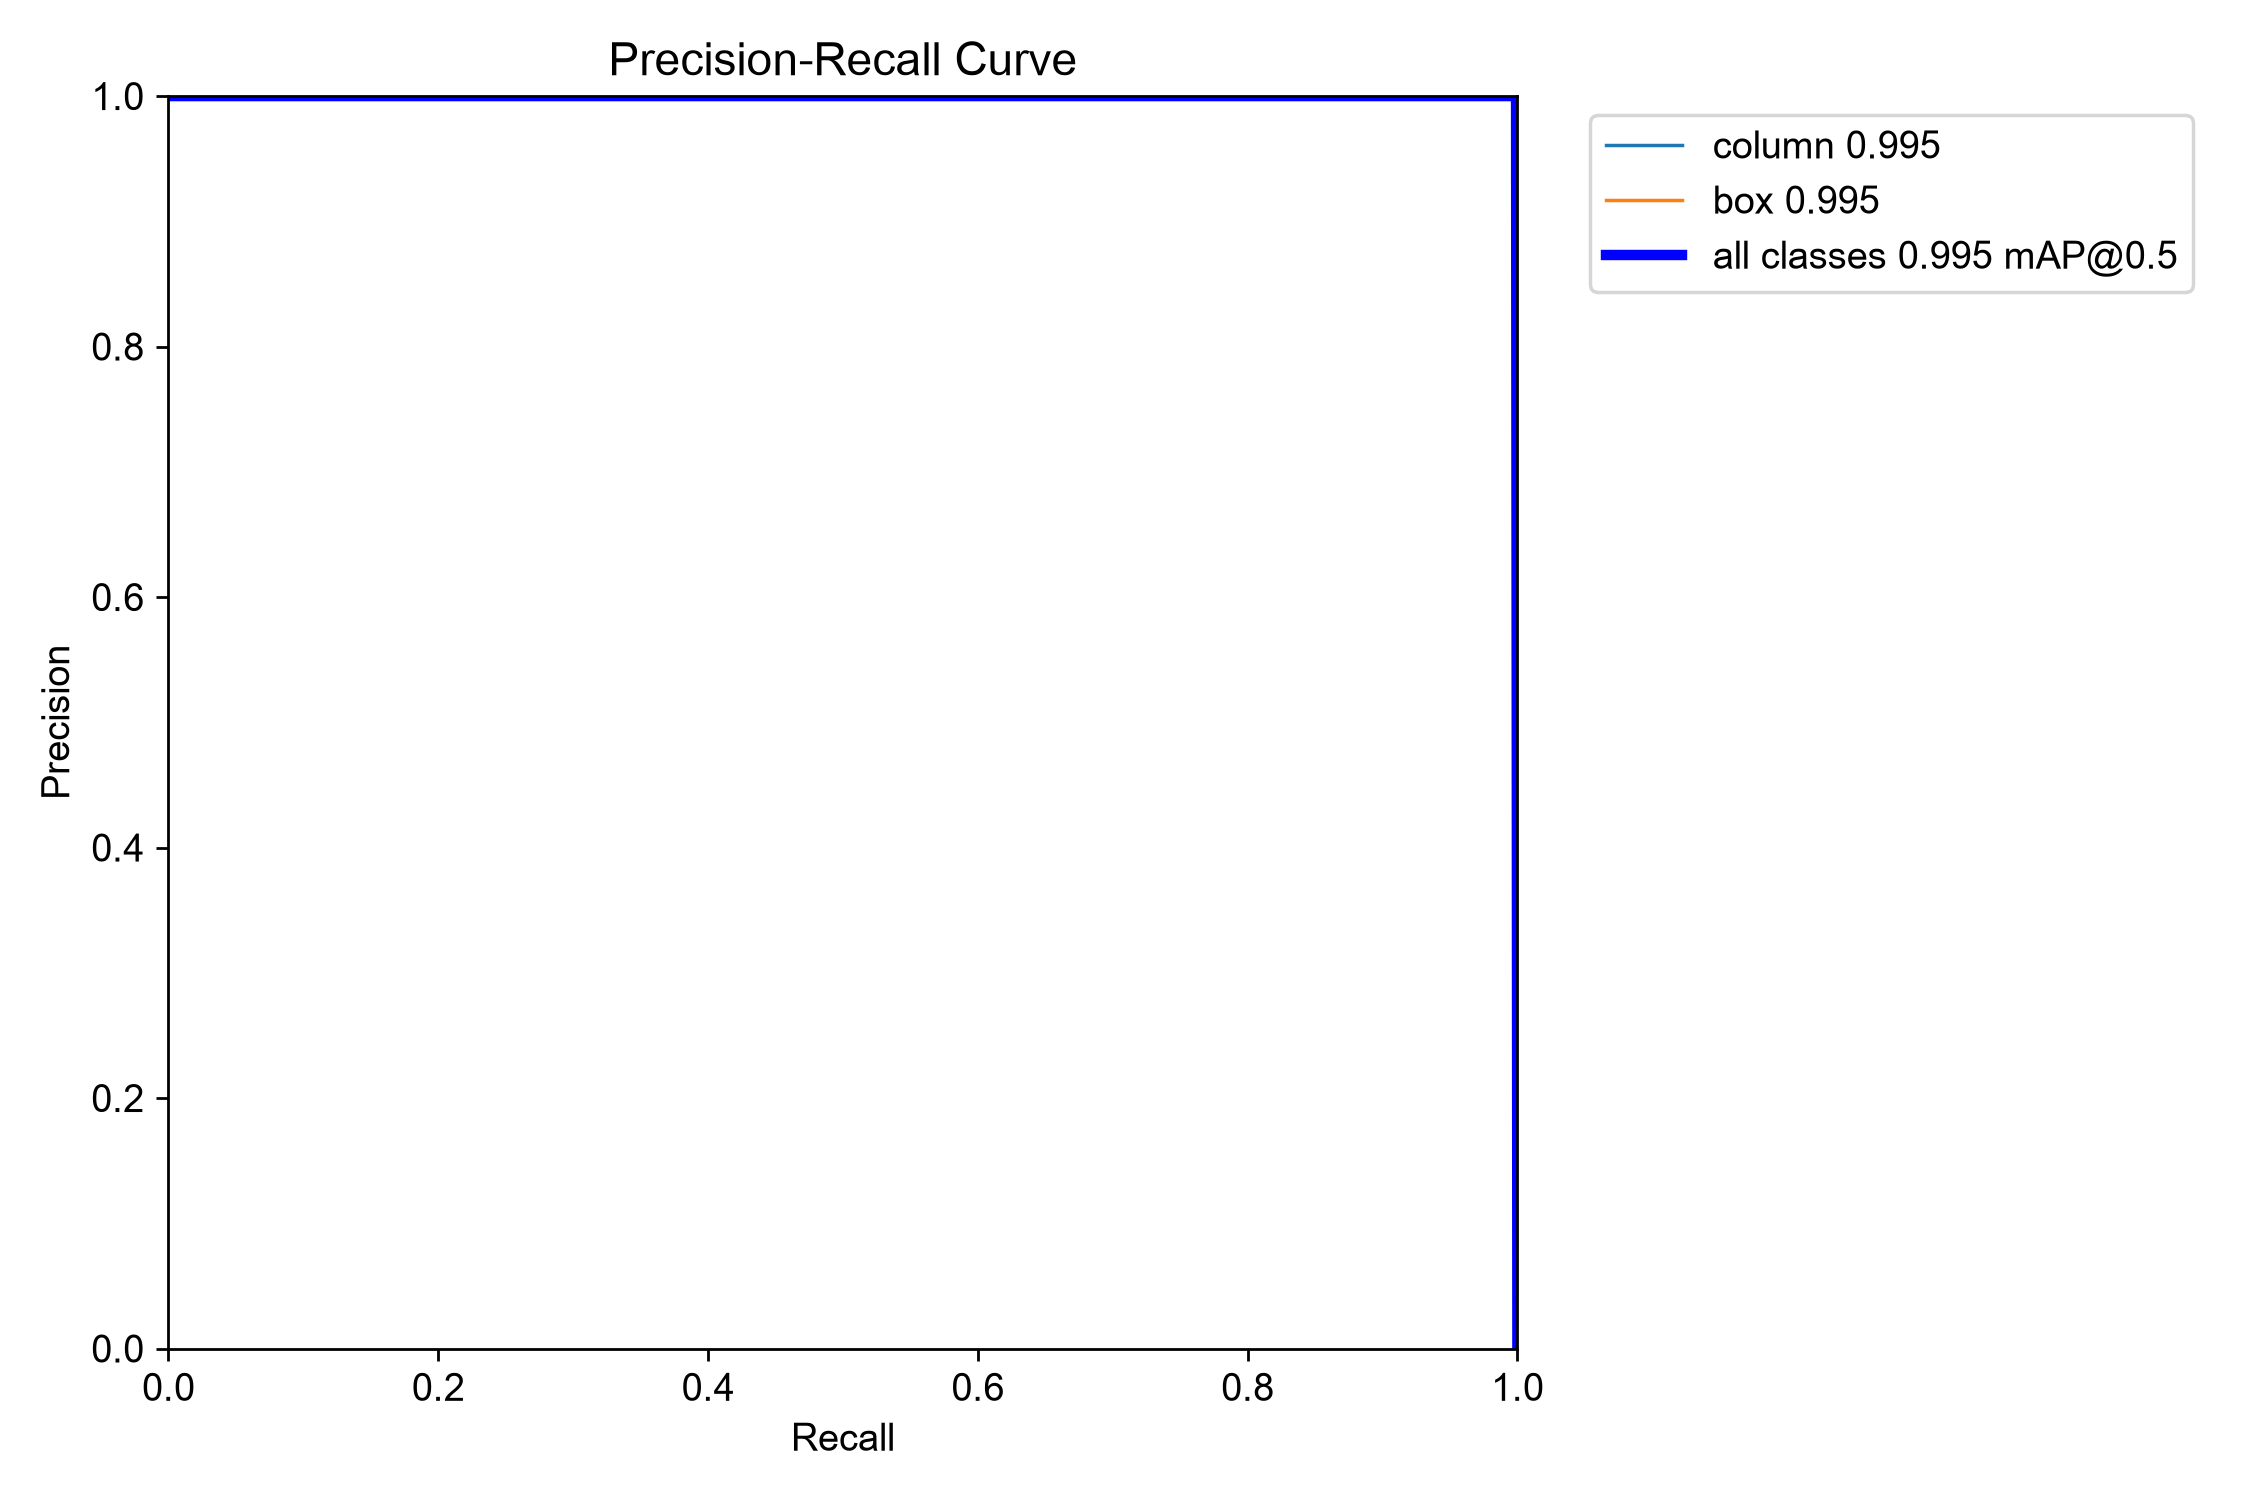

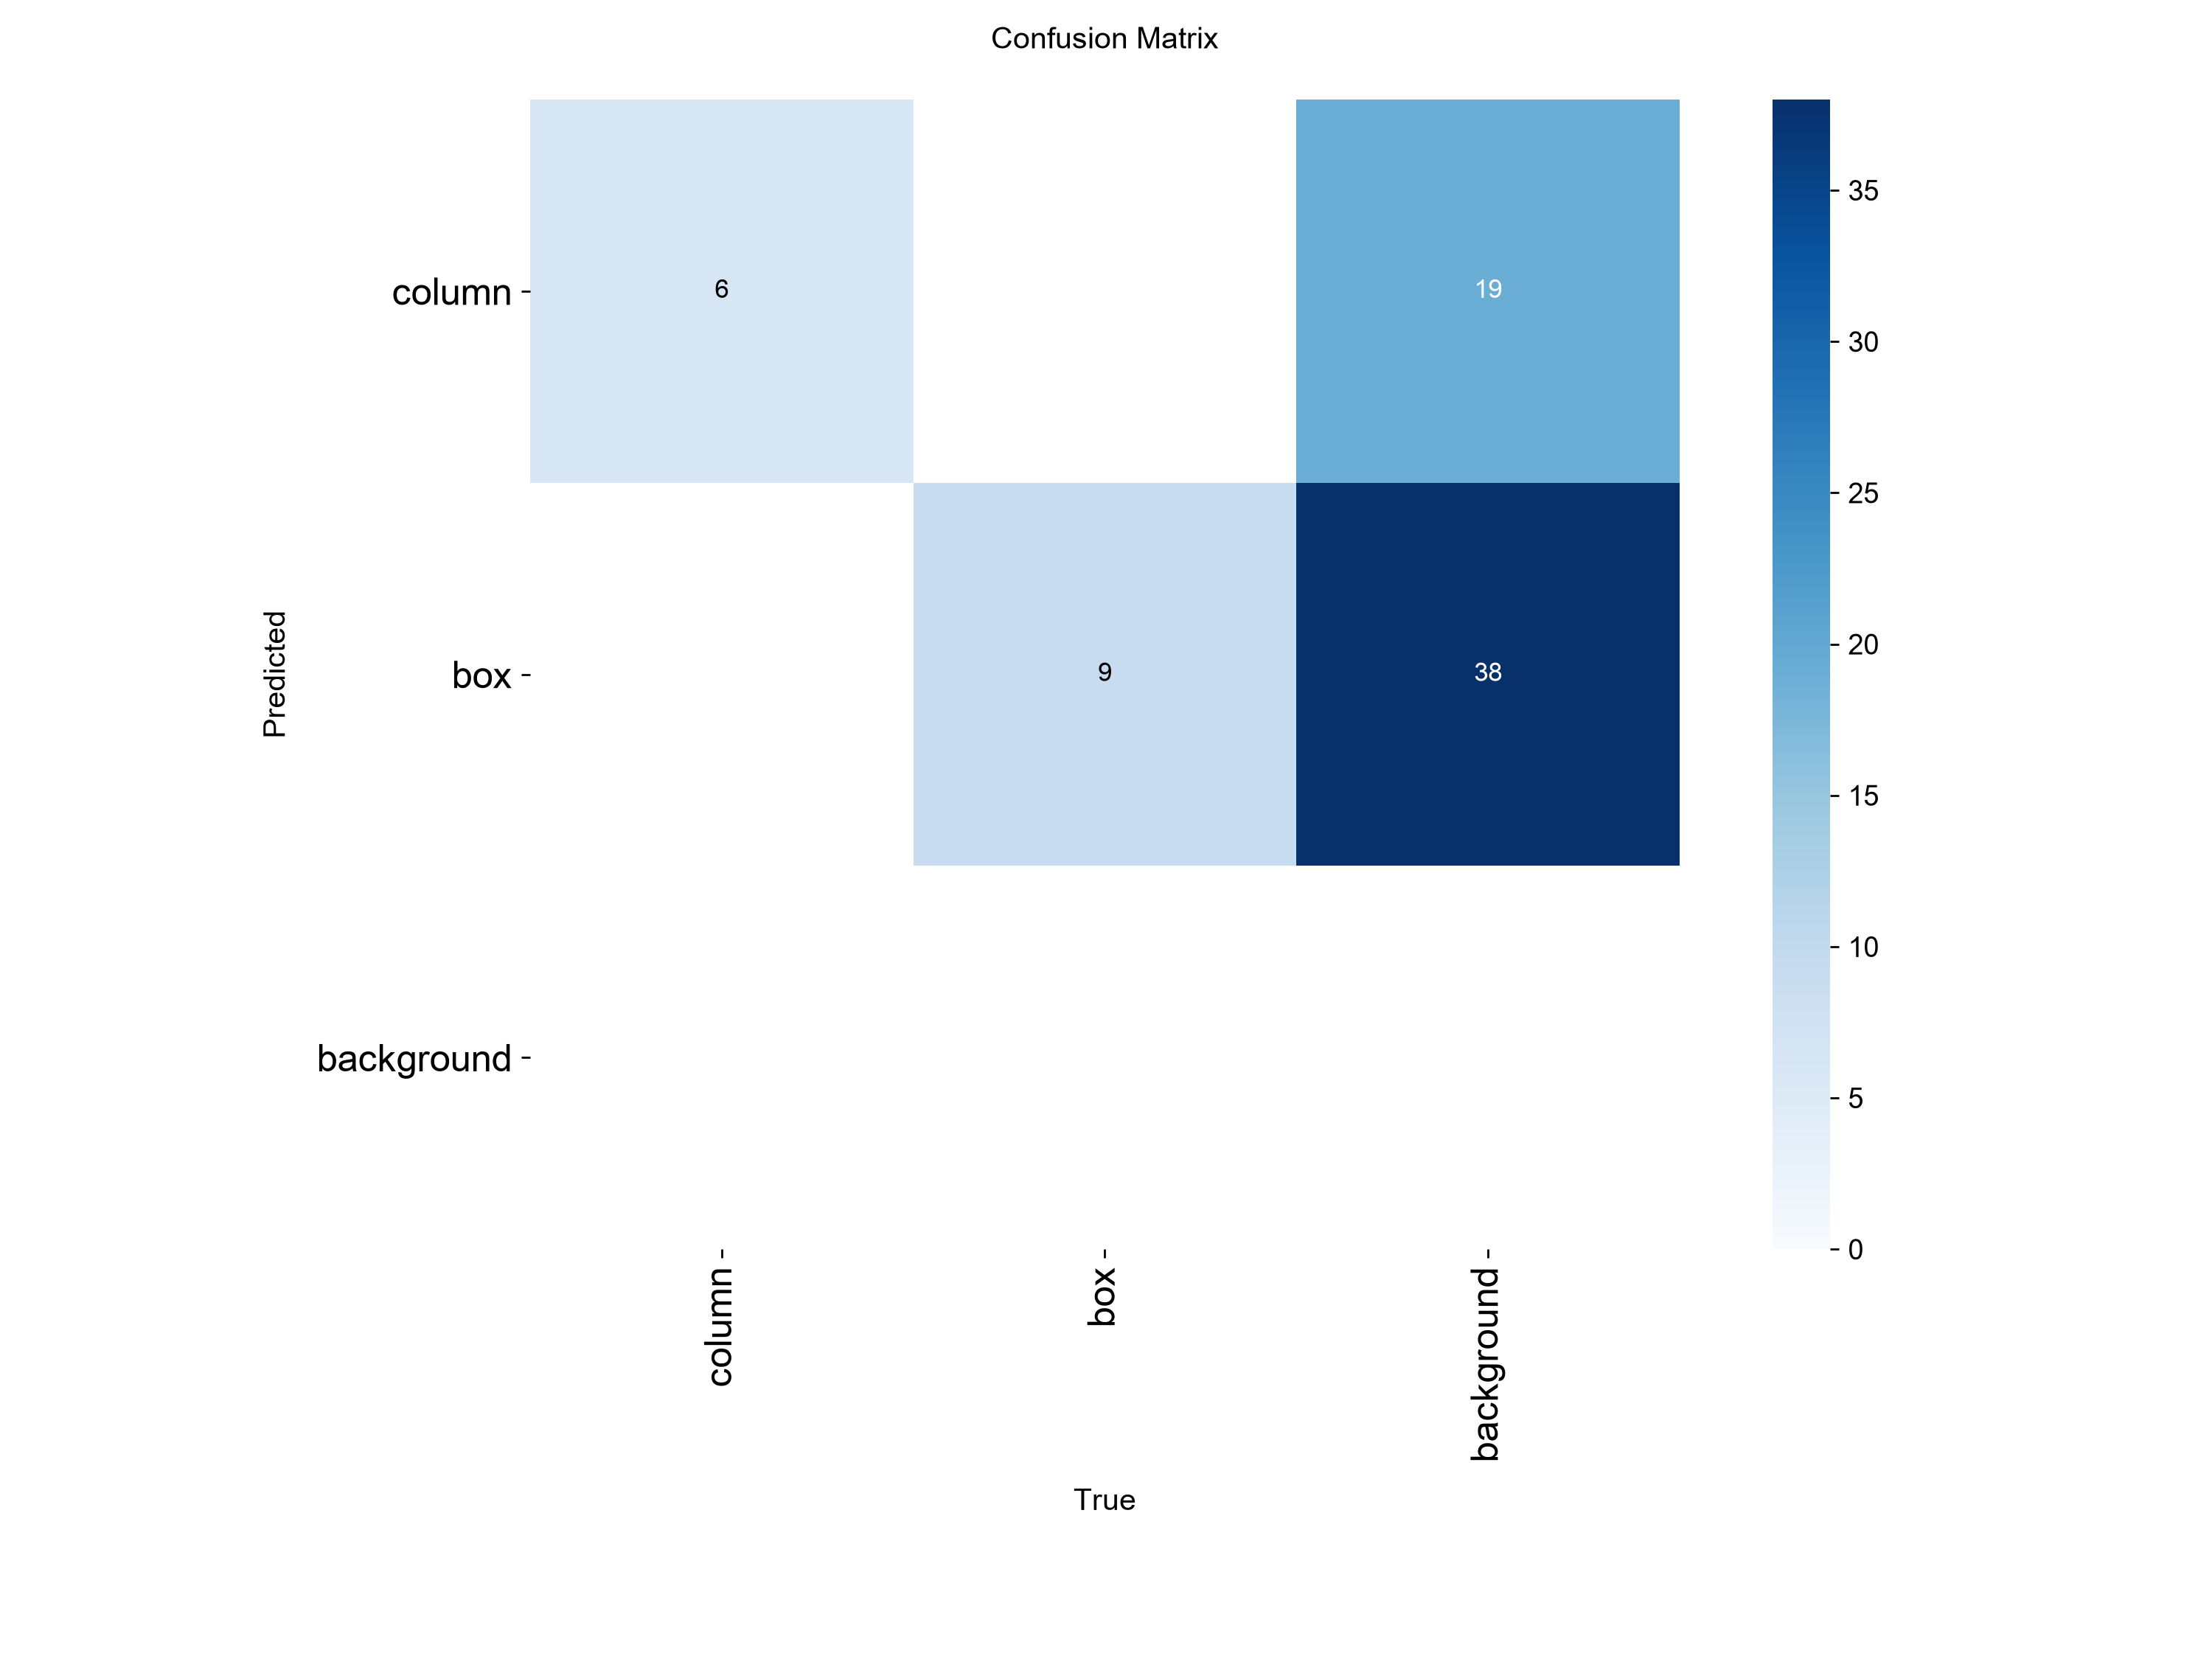

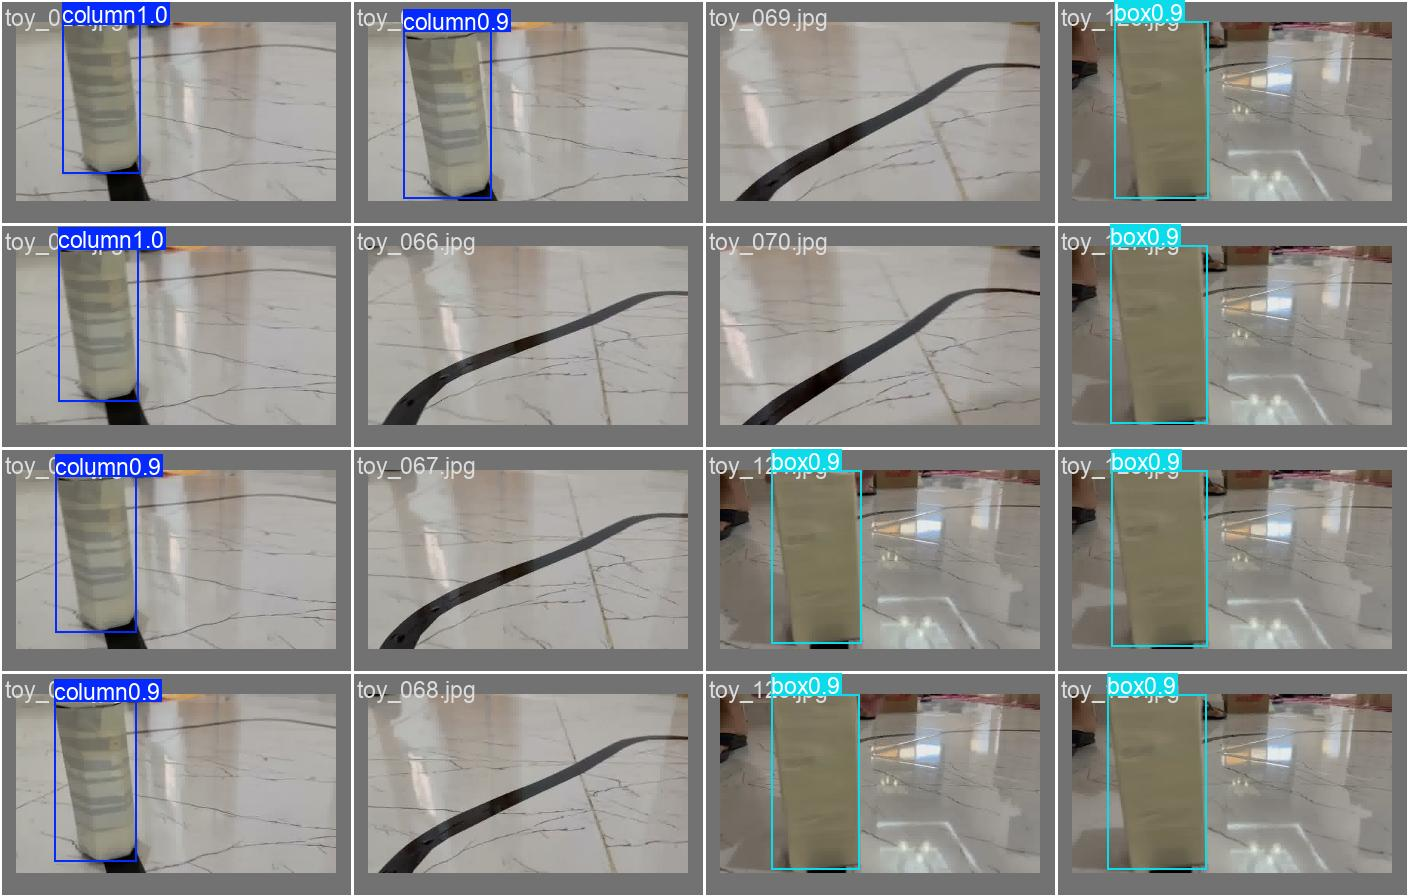

In [7]:
best = YOLO(BEST)

def evaluate(split):
    m = best.val(data=str(DS / "data.yaml"), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, plots=True,
                 project=str(RUNS), name=f"toy_obstacles_{split}", exist_ok=True)
    P, R = float(m.box.mp), float(m.box.mr)
    return m, {"precision": round(P, 3), "recall": round(R, 3), "map50": round(float(m.box.map50), 3),
               "map50_95": round(float(m.box.map), 3), "f1": round(2 * P * R / max(P + R, 1e-9), 3),
               "inference_ms": round(float(m.speed["inference"]), 1)}

m, metrics = evaluate("test")
m_esp, metrics_esp32 = evaluate("test_esp32")
per_class = {m.names[int(c)]: round(float(ap), 3) for c, ap in zip(m.box.ap_class_index, m.box.ap50)}
cm = m.confusion_matrix.matrix
confusion = {"labels": td.CLASSES + ["background"], "matrix": cm.T.astype(int).tolist()}
print("test (real frames)        :", json.dumps(metrics)); print("AP@50 per class:", per_class)
print("test (ESP32-CAM 320 x 240):", json.dumps(metrics_esp32))
for f in ("BoxPR_curve.png", "confusion_matrix.png", "val_batch0_pred.jpg"):
    p = RUNS / "toy_obstacles_test" / f
    if p.exists():
        display(Image(filename=str(p), width=800))

## 5 · Export for the dashboard (Prototype mode)

In [8]:
onnx_path = Path(best.export(format="onnx", imgsz=IMGSZ, opset=17, simplify=True))
shutil.copy(onnx_path, MODELS / "toy_obstacles.onnx")
shutil.copy(BEST, MODELS / "toy_obstacles.pt")
profile = {"name": "Toy track obstacles", "models": [
    {"id": "toy-obstacles", "path": "models/toy_obstacles.onnx", "imgsz": IMGSZ, "conf": 0.4,
     "classes": {"column": "column", "box": "box"}}]}
(MODELS / "proto_toy.json").write_text(json.dumps(profile, indent=2))

reg_path = MODELS / "registry.json"
registry = json.loads(reg_path.read_text())
entry = {
    "id": "toy-obstacles", "mode": "proto", "name": "Toy track obstacle detector",
    "framework": f"{MODEL.split('.')[0].upper()} fine-tuned (Ultralytics {ultralytics.__version__})", "version": "1.0",
    "trained": date.today().isoformat(), "input": f"{IMGSZ} × {IMGSZ}",
    "dataset": {"images": sum(c["real"] for c in counts.values()),
                "split": f"{counts['train']['real']} / {counts['val']['real']} / {counts['test']['real']} real frames",
                "sources": ["Our toy-track video (249 frames), labels from SAM 2 video tracking, checked visually",
                            f"+ {counts['train']['esp32_look']} ESP32-CAM-look copies and {counts['train']['pasted']} "
                            "copy-paste images (training only)"]},
    "example": False, "metrics_source": "held-out test frames (time-block split of the same drive)",
    "metrics": metrics, "per_class": per_class, "confusion": confusion,
    "metrics_variants": [{"label": "Same test frames as 320 × 240 ESP32-CAM-style images", "metrics": metrics_esp32}],
    "training": {"epochs": model.trainer.epoch + 1, "minutes": round(TRAIN_MINUTES, 1),
                 "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"},
}
registry["models"] = [m_ for m_ in registry["models"] if m_.get("id") not in ("toy-car-v1", "toy-obstacles")] + [entry]
reg_path.write_text(json.dumps(registry, indent=2, ensure_ascii=False))
print("exported models/toy_obstacles.onnx + models/proto_toy.json · registry updated")

Ultralytics 8.4.184 🚀 Python-3.12.3 torch-2.14.1+cu132 CPU (Intel Core i7-10750H 2.60GHz)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 1.3 GFLOPs

PyTorch: starting from '/workspace/training/runs/toy_obstacles/weights/best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 6, 2100) (5.2 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 9.3s, saved as '/workspace/training/runs/toy_obstacles/weights/best.onnx' (9.3 MB)

Export complete (13.2s)
Results saved to /workspace/training/runs/toy_obstacles/weights/best.onnx
Predict:         yolo predict task=detect model=/workspace/training/runs/toy_obstacles/weights/best.onnx imgsz=320 
Validate:        yolo val task=detect model=/workspace/training/runs/toy_obstacles/weights/best.onnx imgsz=320 data=/datasets/toy_obstacles/data.yaml 
Visualize:       https://netron.app
exported models/toy_obstacles.onnx + models/proto_toy.json · regis

## 6 · Sanity check: predictions on test frames

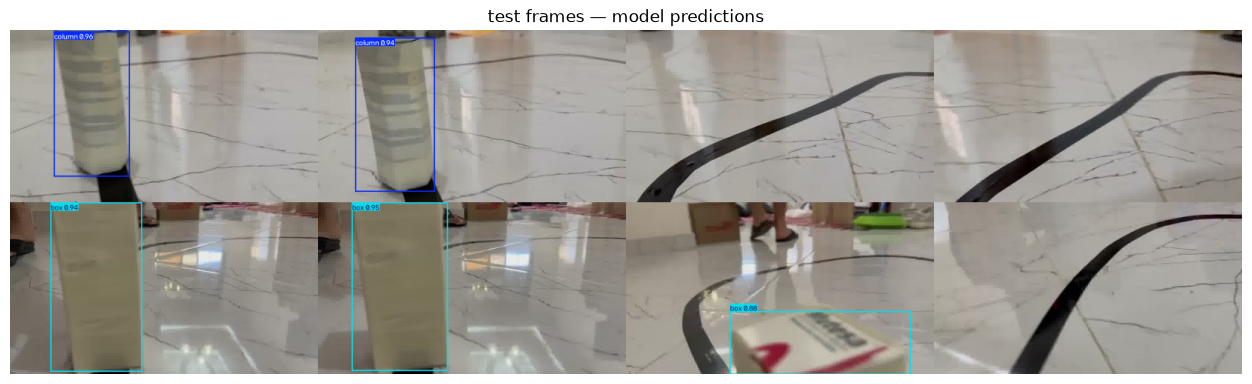

All done. Restart the dashboard to use the model in Prototype mode:  docker compose restart dashboard


In [9]:
files = sorted((DS / "images" / "test").glob("*.jpg"))[::3][:8]
res = best.predict([str(f) for f in files], conf=0.4, verbose=False)
tiles = [cv2.resize(r.plot(), (416, 232)) for r in res]
import numpy as np
while len(tiles) % 4:
    tiles.append(np.zeros_like(tiles[0]))
show(np.vstack([np.hstack(tiles[k:k + 4]) for k in range(0, len(tiles), 4)]), "test frames — model predictions")
print("All done. Restart the dashboard to use the model in Prototype mode:  docker compose restart dashboard")